# Hindi Speech Dataset — Linear Regression, Bayesian Logistic Regression, SVM

This notebook works with `v1_Hindi_train.tgz` (~17GB). Since this is raw audio, not tabular data, we can't feed it directly into linear regression / logistic regression / SVM. The plan:

1. Extract the archive (or peek at it without fully extracting, since it's 17GB).
2. Find any metadata/manifest file (CSV/JSON/TSV) that ships with it — this is where labels (gender, scenario, duration, language, etc.) usually live, similar to `IndicVoices`.
3. Extract numeric **audio features** (duration, MFCCs, pitch, energy) from a **sample** of the audio files — extracting features from all files in a 17GB set will be slow, so we sample first and scale up only if needed.
4. Build a clean feature dataframe.
5. Pick a real target column once we see what's available, then run:
   - **Linear Regression** — predicting a continuous target (e.g. duration, or a continuous feature)
   - **Bayesian Logistic Regression** — predicting a binary target (e.g. gender, scenario) with uncertainty estimates, using PyMC
   - **SVM** — classification on the same binary/multiclass target

Run the cells top to bottom. Where you see `# >>> EDIT`, that's a spot to plug in your actual paths/column names once we see the real data.

In [14]:
!pip install -q pandas numpy scikit-learn pymc arviz


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# 1. Setup
import os
import tarfile
import glob
import json

DATA_PATH = "v1_Hindi_train.tgz"   # >>> EDIT: full path to your downloaded file
EXTRACT_DIR = "hindi_train_extracted"

print("File exists:", os.path.exists(DATA_PATH))
if os.path.exists(DATA_PATH):
    print("Size (GB):", round(os.path.getsize(DATA_PATH) / 1e9, 2))

File exists: True
Size (GB): 14.32


## 2. Peek inside the archive before extracting

17GB is large, so first list the contents without extracting everything. This tells us the folder structure and whether a metadata file exists.

In [2]:
# List first ~50 entries in the tar without extracting
with tarfile.open(DATA_PATH, "r:gz") as tar:
    members = tar.getnames()

print("Total entries:", len(members))
for name in members[:50]:
    print(name)

Total entries: 14899
Hindi/v1/train
Hindi/v1/train/003b940f-92f2-4523-a5cc-67ae7dc88468_0.json
Hindi/v1/train/003b940f-92f2-4523-a5cc-67ae7dc88468_0.wav
Hindi/v1/train/008c17f6-3a30-4877-aae3-d5a0db0482af_1.json
Hindi/v1/train/008c17f6-3a30-4877-aae3-d5a0db0482af_1.wav
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_0.json
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_0.wav
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_1.json
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_1.wav
Hindi/v1/train/01f4288d-aa9a-48c6-9941-f1d76a6141b7_1.json
Hindi/v1/train/01f4288d-aa9a-48c6-9941-f1d76a6141b7_1.wav
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_0.json
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_0.wav
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_1.json
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_1.wav
Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_0.json
Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_0.wav
Hindi/v1/train/0479697b-1e6b

In [3]:
# Look specifically for metadata-like files (csv/json/tsv/txt) anywhere in the archive
meta_candidates = [m for m in members if m.lower().endswith((".csv", ".json", ".tsv", ".jsonl"))]
print("Possible metadata files found:", len(meta_candidates))
for m in meta_candidates[:20]:
    print(m)

Possible metadata files found: 7449
Hindi/v1/train/003b940f-92f2-4523-a5cc-67ae7dc88468_0.json
Hindi/v1/train/008c17f6-3a30-4877-aae3-d5a0db0482af_1.json
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_0.json
Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_1.json
Hindi/v1/train/01f4288d-aa9a-48c6-9941-f1d76a6141b7_1.json
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_0.json
Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_1.json
Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_0.json
Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_1.json
Hindi/v1/train/0642b428-2ce5-4e24-b83f-bd1f81bfda50_0.json
Hindi/v1/train/0642b428-2ce5-4e24-b83f-bd1f81bfda50_1.json
Hindi/v1/train/065367c0-39b9-4f5b-a595-8ed3e5038106_0.json
Hindi/v1/train/0679ea9c-9274-411d-a566-77a46679e66a_0.json
Hindi/v1/train/0793789e-d233-44a3-b715-fd6d42a6c53e_0.json
Hindi/v1/train/0793789e-d233-44a3-b715-fd6d42a6c53e_1.json
Hindi/v1/train/091c1901-8b0e-4f94-92b6-6025595b3012_0.json
Hindi/v1/train/091c1

## 3. Extract

If a metadata file was found above, we only need to extract that file plus a *sample* of audio for feature extraction — not the whole 17GB.

If nothing was found, we extract everything (make sure you have >17GB free disk space) or extract a sampled subset (recommended).

In [4]:
# Extract just the metadata file(s), if any were found
os.makedirs(EXTRACT_DIR, exist_ok=True)

with tarfile.open(DATA_PATH, "r:gz") as tar:
    for m in meta_candidates:
        tar.extract(m, path=EXTRACT_DIR)

extracted_meta_paths = [os.path.join(EXTRACT_DIR, m) for m in meta_candidates]
extracted_meta_paths

C:\Users\Kshitij\AppData\Local\Temp\ipykernel_16208\1692144775.py:6: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(m, path=EXTRACT_DIR)


['hindi_train_extracted\\Hindi/v1/train/003b940f-92f2-4523-a5cc-67ae7dc88468_0.json',
 'hindi_train_extracted\\Hindi/v1/train/008c17f6-3a30-4877-aae3-d5a0db0482af_1.json',
 'hindi_train_extracted\\Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_0.json',
 'hindi_train_extracted\\Hindi/v1/train/012a3c2f-2036-4c3a-bca3-481038a74a9d_1.json',
 'hindi_train_extracted\\Hindi/v1/train/01f4288d-aa9a-48c6-9941-f1d76a6141b7_1.json',
 'hindi_train_extracted\\Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_0.json',
 'hindi_train_extracted\\Hindi/v1/train/046068d4-b337-44b9-90d4-79d82670720c_1.json',
 'hindi_train_extracted\\Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_0.json',
 'hindi_train_extracted\\Hindi/v1/train/0479697b-1e6b-4898-9591-b781f3d5fef5_1.json',
 'hindi_train_extracted\\Hindi/v1/train/0642b428-2ce5-4e24-b83f-bd1f81bfda50_0.json',
 'hindi_train_extracted\\Hindi/v1/train/0642b428-2ce5-4e24-b83f-bd1f81bfda50_1.json',
 'hindi_train_extracted\\Hindi/v1/train/065367c0-39b9-

In [ ]:
# OPTIONAL: extract a random SAMPLE of audio files (e.g. 2000) instead of all ~17GB
# Skip this cell if you already extracted everything, or if metadata is enough for now.
import random

audio_members = [m for m in members if m.lower().endswith((".wav", ".flac", ".mp3"))]
print("Total audio files in archive:", len(audio_members))

N_SAMPLE = 2000  # >>> EDIT: increase later if needed
random.seed(42)
sample_members = random.sample(audio_members, min(N_SAMPLE, len(audio_members)))

with tarfile.open(DATA_PATH, "r:gz") as tar:
    for m in sample_members:
        tar.extract(m, path=EXTRACT_DIR)

print("Extracted", len(sample_members), "audio files to", EXTRACT_DIR)

## 4. Load metadata (if found) into a DataFrame

Adjust the loader depending on whether it's CSV/TSV/JSON/JSONL.

In [7]:
import glob
import pandas as pd

json_dir = "hindi_train_extracted/Hindi/v1/train"
json_files = glob.glob(f"{json_dir}/*.json") + glob.glob(f"{json_dir}/*.jsonl")

print("Found:", len(json_files), "files")
print(json_files[:5])

# If it's many small per-utterance JSON files, load and combine them
records = []
for jf in json_files:
    try:
        records.append(pd.read_json(jf, typ="series"))
    except ValueError:
        # fallback: multi-record JSON lines file
        records.append(pd.read_json(jf, lines=True))

if records and isinstance(records[0], pd.Series):
    df_meta = pd.DataFrame(records)
else:
    df_meta = pd.concat(records, ignore_index=True)

print(df_meta.shape)
df_meta.head()

Found: 7449 files
['hindi_train_extracted/Hindi/v1/train\\003b940f-92f2-4523-a5cc-67ae7dc88468_0.json', 'hindi_train_extracted/Hindi/v1/train\\008c17f6-3a30-4877-aae3-d5a0db0482af_1.json', 'hindi_train_extracted/Hindi/v1/train\\012a3c2f-2036-4c3a-bca3-481038a74a9d_0.json', 'hindi_train_extracted/Hindi/v1/train\\012a3c2f-2036-4c3a-bca3-481038a74a9d_1.json', 'hindi_train_extracted/Hindi/v1/train\\01f4288d-aa9a-48c6-9941-f1d76a6141b7_1.json']
(7449, 18)


,language,audio_raw_duration,scenario,task_name,gender,age_group,job_type,qualification,area,district,state,occupation,verbatim,normalized,audio_segmented_duration,speaker_id,verification_report,prompt
0,Hindi,252.0,Conversation,Conversation,Male,18-30,Student,Upto 12th,Rural,Karauli,Rajasthan,Khel,"[{'end': 3.581, 'text': 'हलो जी', 'start': 2.9...","[{'end': 3.581, 'text': 'हलो [hello] जी', 'sta...",98.513,S4258602700393085,"{'sst': False, 'comments': '', 'decision': 'ex...",Parent|Teacher|Teacher calling parent to pick ...
1,Hindi,246.0,Conversation,Conversation,Male,60+,Unemployed,Post Grad + PhD,Rural,Sonbhadra,Uttar Pradesh,Retired Teacher,"[{'end': 4.193, 'text': 'हाँ हेलो अभिषेक', 'st...","[{'end': 4.193, 'text': 'हाँ हेलो [Hello] अभिष...",103.771,S4259117200359895,"{'sst': False, 'comments': '', 'decision': 'ex...",HR|IT manager|our company signed new gaming co...
2,Hindi,162.0,Conversation,Conversation,Female,18-30,Student,Upto 12th,Urban,Jodhpur,Rajasthan,Student,"[{'end': 2.457, 'text': 'हेलो', 'start': 1.913...","[{'end': 2.457, 'text': 'हेलो [hello]', 'start...",68.818,S4257509800382215,"{'sst': False, 'comments': '', 'decision': 'ex...",Citizen|Traffic Police|Complaing about the mis...
3,Hindi,162.0,Conversation,Conversation,Female,18-30,Student,Undergrad and Grad.,Urban,Jodhpur,Rajasthan,Student,"[{'end': 8.186, 'text': 'नमस्ते ', 'start': 7....","[{'end': 8.186, 'text': 'नमस्ते ', 'start': 7....",50.714,S4259671000340700,"{'sst': False, 'comments': '', 'decision': 'ex...",Citizen|Traffic Police|Complaing about the mis...
4,Hindi,220.0,Conversation,Conversation,Female,30-45,Blue Collar,Upto 12th,Urban,Jodhpur,Rajasthan,Tailar,"[{'end': 2.283, 'text': 'हलो', 'start': 1.671,...","[{'end': 2.283, 'text': 'हलो [hello]', 'start'...",154.102,S4258986700320501,"{'sst': False, 'comments': '', 'decision': 'ex...","Passanger|Policeman|Sir, few days ago, my mobi..."


In [8]:
# Skip audio feature extraction — the metadata already has good numeric + categorical fields
df = df_meta.copy()

# Quick sanity check
df[["audio_raw_duration", "audio_segmented_duration", "gender", "scenario",
    "age_group", "qualification", "area", "state"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7449 entries, 0 to 7448
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   audio_raw_duration        7449 non-null   float64
 1   audio_segmented_duration  7449 non-null   float64
 2   gender                    7449 non-null   object 
 3   scenario                  7449 non-null   object 
 4   age_group                 7449 non-null   object 
 5   qualification             7449 non-null   object 
 6   area                      7449 non-null   object 
 7   state                     7449 non-null   object 
dtypes: float64(2), object(6)
memory usage: 465.7+ KB


In [9]:
from sklearn.preprocessing import LabelEncoder

# Encode categorical columns we'll use as features
cat_cols = ["scenario", "age_group", "job_type", "qualification", "area", "state"]
df_enc = df.dropna(subset=cat_cols + ["audio_raw_duration", "audio_segmented_duration", "gender"]).copy()

encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    df_enc[c + "_enc"] = le.fit_transform(df_enc[c])
    encoders[c] = le

feature_cols = ["audio_raw_duration"] + [c + "_enc" for c in cat_cols]
print(feature_cols)
df_enc[feature_cols].head()

['audio_raw_duration', 'scenario_enc', 'age_group_enc', 'job_type_enc', 'qualification_enc', 'area_enc', 'state_enc']


,audio_raw_duration,scenario_enc,age_group_enc,job_type_enc,qualification_enc,area_enc,state_enc
0,252.0,0,0,1,3,0,1
1,246.0,0,3,2,1,0,2
2,162.0,0,0,1,3,1,1
3,162.0,0,0,1,2,1,1
4,220.0,0,1,0,3,1,1


Linear Regression — predict audio_segmented_duration from audio_raw_duration + context:

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

X = df_enc[feature_cols].values
y = df_enc["audio_segmented_duration"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lin_reg = LinearRegression()
lin_reg.fit(X_train_s, y_train)
y_pred = lin_reg.predict(X_test_s)

print("R^2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R^2: 0.7807609570801368
RMSE: 17.43400948253493


Bayesian Logistic Regression — predict gender (binary):

In [16]:
import pymc as pm
import arviz as az
import numpy as np


In [22]:
import pytensor
pytensor.config.mode = "FAST_COMPILE"
pytensor.config.cxx = ""  # disables C compilation, falls back to Python

In [26]:

le_gender = LabelEncoder()
df_bin = df_enc[df_enc["gender"].isin(["Male", "Female"])].copy()
y_gender = le_gender.fit_transform(df_bin["gender"])  # Female=0, Male=1 (check order)

X_g = df_bin[feature_cols].values
Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_g, y_gender, test_size=0.2, random_state=42, stratify=y_gender
)
scaler_g = StandardScaler()
Xg_train_s = scaler_g.fit_transform(Xg_train)
Xg_test_s = scaler_g.transform(Xg_test)

with bayes_logreg:
    approx = pm.fit(n=20000, method="advi", random_seed=42)
    trace = approx.sample(1000)

az.summary(trace, var_names=["beta0", "betas"])

c:\Users\Kshitij\AppData\Local\Programs\Python\Python312\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Finished [100%]: Average Loss = 3,756.4


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta0,0.359,0.033,0.31,0.41,898,804,nan,0.0011,0.00086
betas[0],-0.112,0.038,-0.17,-0.05,1071,933,nan,0.0012,0.00092
betas[1],-0.108,0.039,-0.17,-0.045,1010,912,nan,0.0012,0.00096
betas[2],0.13,0.035,0.075,0.19,938,837,nan,0.0011,0.00079
betas[3],0.041,0.032,-0.011,0.094,651,948,nan,0.0013,0.00073
betas[4],0.406,0.035,0.35,0.46,1027,898,nan,0.0011,0.00088
betas[5],-0.665,0.035,-0.72,-0.61,990,940,nan,0.0011,0.00082
betas[6],-0.038,0.036,-0.096,0.017,1040,907,nan,0.0011,0.0009


In [28]:
import arviz as az
import numpy as np

le_gender = LabelEncoder()
df_bin = df_enc[df_enc["gender"].isin(["Male", "Female"])].copy()
y_gender = le_gender.fit_transform(df_bin["gender"])  # Female=0, Male=1 (check order)

X_g = df_bin[feature_cols].values
Xg_train, Xg_test, yg_train, yg_test = train_test_split(
    X_g, y_gender, test_size=0.2, random_state=42, stratify=y_gender
)
scaler_g = StandardScaler()
Xg_train_s = scaler_g.fit_transform(Xg_train)
Xg_test_s = scaler_g.transform(Xg_test)

with bayes_logreg:
    approx = pm.fit(n=20000, method="advi", random_seed=42)
    trace = approx.sample(1000)

az.summary(trace, var_names=["beta0", "betas"])

c:\Users\Kshitij\AppData\Local\Programs\Python\Python312\Lib\site-packages\rich\live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Finished [100%]: Average Loss = 3,756.4


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
beta0,0.358,0.034,0.31,0.41,953,786,nan,0.0011,0.0008
betas[0],-0.111,0.038,-0.17,-0.047,1014,984,nan,0.0012,0.00078
betas[1],-0.109,0.037,-0.17,-0.051,1021,958,nan,0.0012,0.00082
betas[2],0.13,0.035,0.071,0.19,1027,946,nan,0.0011,0.00075
betas[3],0.043,0.033,-0.0099,0.098,932,959,nan,0.0011,0.00074
betas[4],0.405,0.036,0.35,0.46,1070,843,nan,0.0011,0.00078
betas[5],-0.664,0.036,-0.72,-0.61,1000,929,nan,0.0011,0.00083
betas[6],-0.038,0.035,-0.096,0.017,1034,943,nan,0.0011,0.00076


In [30]:
beta0_samples = trace.posterior["beta0"].values.reshape(-1)
betas_samples = trace.posterior["betas"].values.reshape(-1, Xg_train_s.shape[1])

logits_test = Xg_test_s @ betas_samples.T + beta0_samples[None, :]
p_test_mean = (1 / (1 + np.exp(-logits_test))).mean(axis=1)
y_pred_bayes = (p_test_mean >= 0.5).astype(int)

from sklearn.metrics import accuracy_score, classification_report
print("Accuracy:", accuracy_score(yg_test, y_pred_bayes))
print(classification_report(yg_test, y_pred_bayes))

Accuracy: 0.6560810810810811
              precision    recall  f1-score   support

           0       0.59      0.58      0.59       623
           1       0.70      0.71      0.71       857

    accuracy                           0.66      1480
   macro avg       0.65      0.65      0.65      1480
weighted avg       0.65      0.66      0.66      1480



SVM — same target, for comparison:

In [31]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
svm.fit(Xg_train_s, yg_train)
y_pred_svm = svm.predict(Xg_test_s)

print("Accuracy:", accuracy_score(yg_test, y_pred_svm))
print(classification_report(yg_test, y_pred_svm))

Accuracy: 0.8006756756756757
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       623
           1       0.86      0.78      0.82       857

    accuracy                           0.80      1480
   macro avg       0.80      0.80      0.80      1480
weighted avg       0.81      0.80      0.80      1480



Linear Regression — actual vs predicted, and residuals

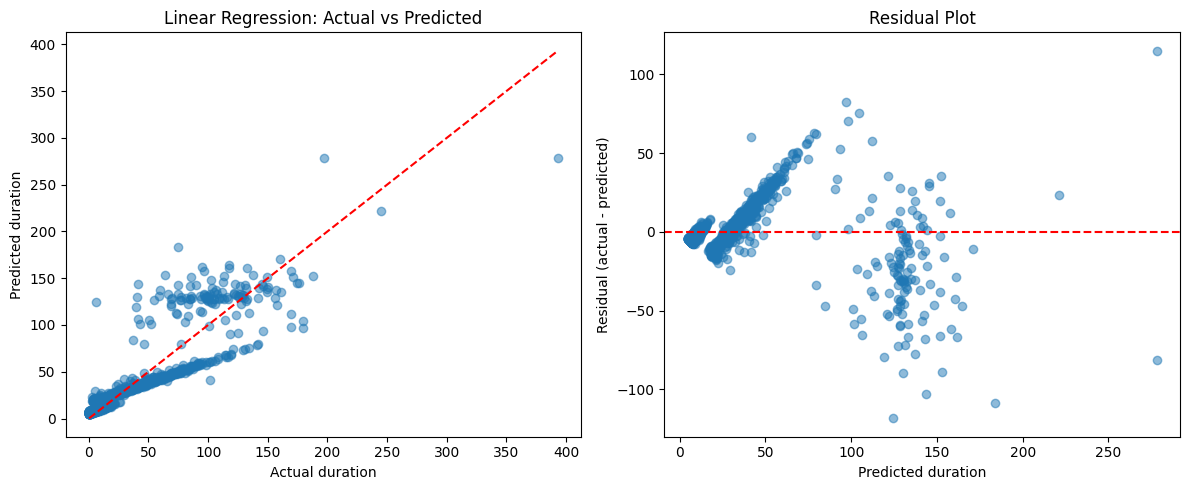

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_xlabel("Actual duration")
axes[0].set_ylabel("Predicted duration")
axes[0].set_title("Linear Regression: Actual vs Predicted")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color='r', linestyle='--')
axes[1].set_xlabel("Predicted duration")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

- Left: points close to the red diagonal = good predictions. Scattered far off = poor fit.
- Right: residuals should look like a random cloud around 0 with no pattern. A funnel or curve shape means the model is missing something.

Bayesian Logistic Regression — posterior distributions

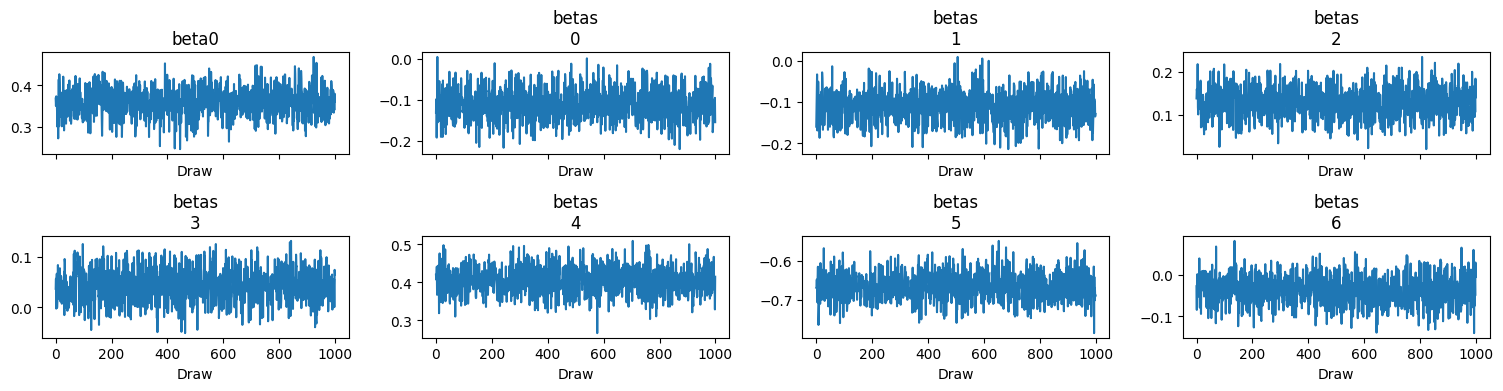

In [33]:
az.plot_trace(trace, var_names=["beta0", "betas"])
plt.tight_layout()
plt.show()

- Each row = one coefficient. Left plots show the posterior distribution (range of plausible values); right plots show the sampling trace (should look like random noise, not trends — confirms it converged).
- If a coefficient's distribution is centered near 0, that feature isn't influencing the prediction much. If it's clearly positive or negative and away from 0, it matters.

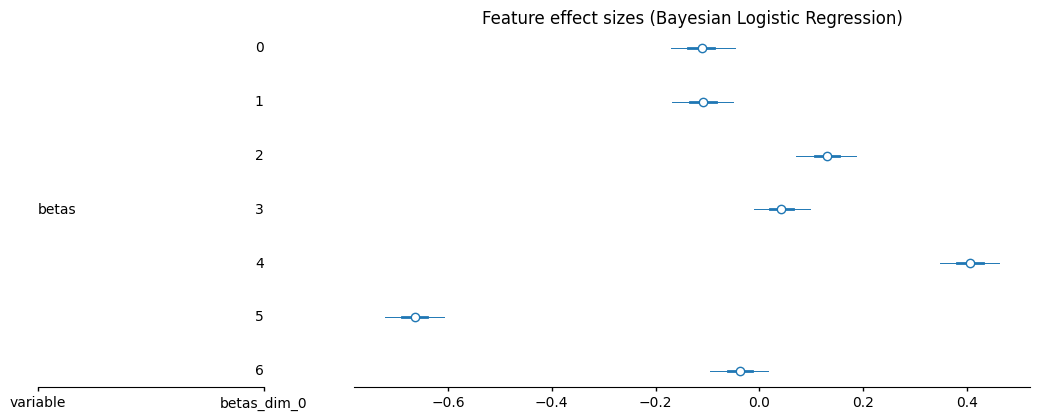

In [34]:
az.plot_forest(trace, var_names=["betas"], combined=True)
plt.title("Feature effect sizes (Bayesian Logistic Regression)")
plt.show()

- Dots = the most likely coefficient value per feature; horizontal lines = uncertainty range (credible interval). Lines crossing 0 mean "not confidently different from no effect."

Confusion matrices — Bayesian vs SVM

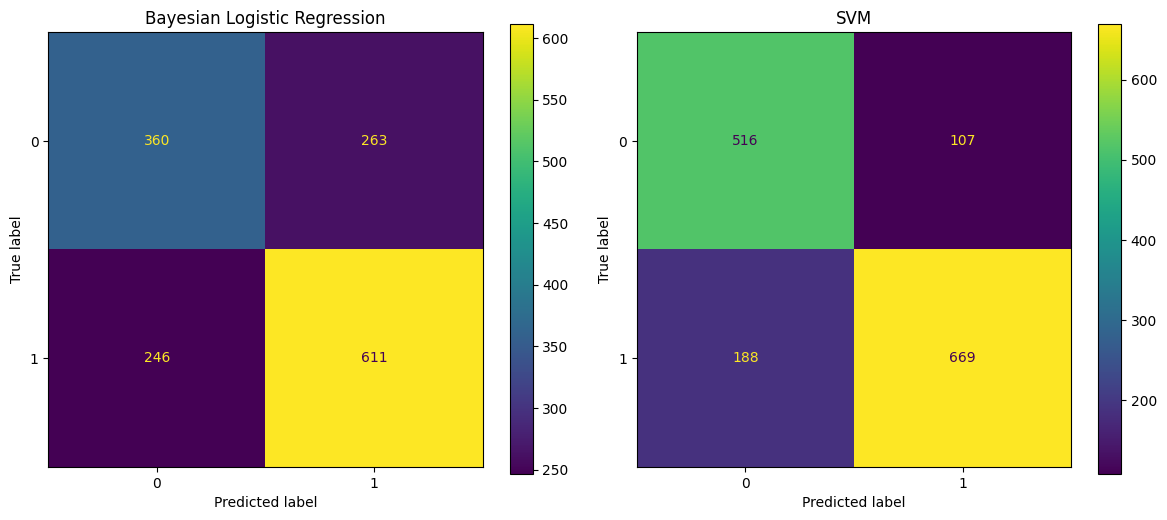

In [35]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(yg_test, y_pred_bayes, ax=axes[0])
axes[0].set_title("Bayesian Logistic Regression")
ConfusionMatrixDisplay.from_predictions(yg_test, y_pred_svm, ax=axes[1])
axes[1].set_title("SVM")
plt.tight_layout()
plt.show()

- Diagonal cells = correct predictions; off-diagonal = mistakes. Bigger numbers on the diagonal = better model.

ROC curves — Bayesian vs SVM

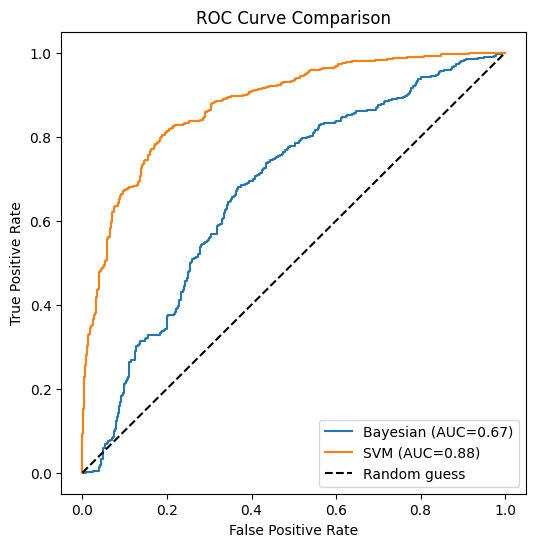

In [36]:
from sklearn.metrics import roc_curve, auc

fpr_b, tpr_b, _ = roc_curve(yg_test, p_test_mean)
svm_scores = svm.decision_function(Xg_test_s)
fpr_s, tpr_s, _ = roc_curve(yg_test, svm_scores)

plt.figure(figsize=(6, 6))
plt.plot(fpr_b, tpr_b, label=f"Bayesian (AUC={auc(fpr_b, tpr_b):.2f})")
plt.plot(fpr_s, tpr_s, label=f"SVM (AUC={auc(fpr_s, tpr_s):.2f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

- Curve closer to the top-left corner = better. AUC closer to 1.0 = better; 0.5 = no better than guessing.

Accuracy comparison bar chart

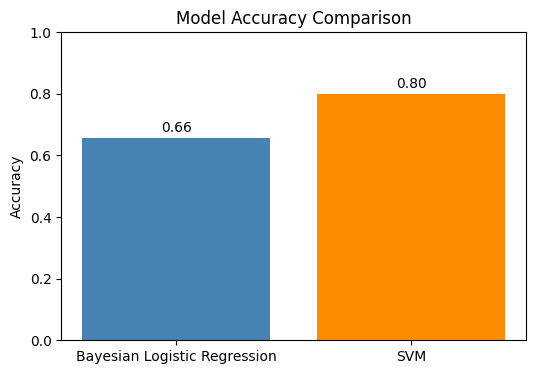

In [37]:
results = pd.DataFrame({
    "model": ["Bayesian Logistic Regression", "SVM"],
    "accuracy": [accuracy_score(yg_test, y_pred_bayes), accuracy_score(yg_test, y_pred_svm)]
})

plt.figure(figsize=(6, 4))
plt.bar(results["model"], results["accuracy"], color=["steelblue", "darkorange"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
for i, v in enumerate(results["accuracy"]):
    plt.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.show()

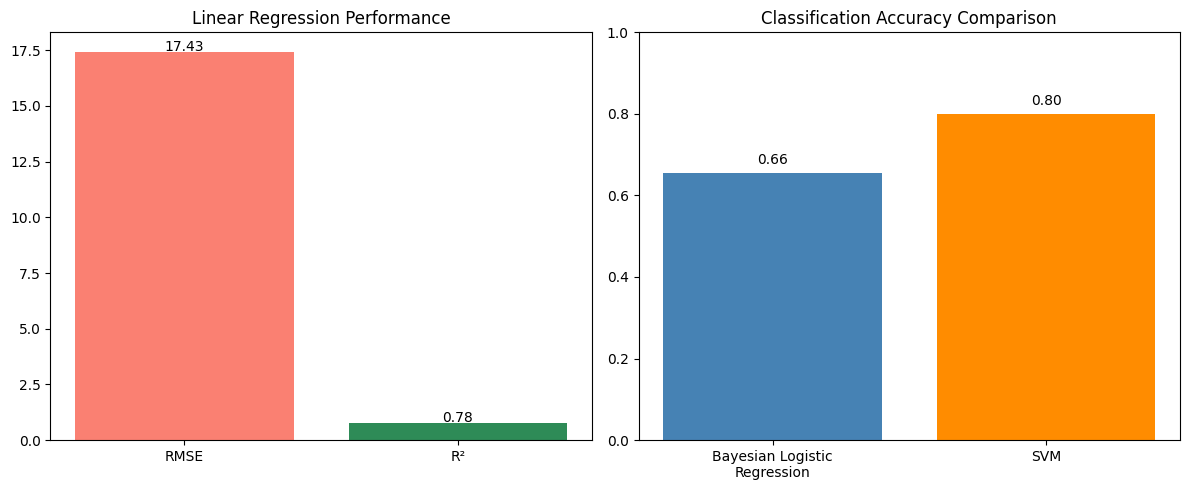

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Linear regression metrics
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Classification metrics
bayes_acc = accuracy_score(yg_test, y_pred_bayes)
svm_acc = accuracy_score(yg_test, y_pred_svm)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: Linear Regression error metrics
axes[0].bar(["RMSE", "R²"], [rmse, r2], color=["salmon", "seagreen"])
axes[0].set_title("Linear Regression Performance")
for i, v in enumerate([rmse, r2]):
    axes[0].text(i, v + 0.02, f"{v:.2f}", ha="center")

# Right: Classification accuracy
axes[1].bar(["Bayesian Logistic\nRegression", "SVM"], [bayes_acc, svm_acc],
            color=["steelblue", "darkorange"])
axes[1].set_ylim(0, 1)
axes[1].set_title("Classification Accuracy Comparison")
for i, v in enumerate([bayes_acc, svm_acc]):
    axes[1].text(i, v + 0.02, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.show()